# 第 12 步：我怎样合成三个因子并形成第一张目标持仓表

<!-- SNAPSHOT_NOTE -->
## 我的数据准备说明

我在本页记录的是完整快照上的实际运行。如果我从 GitHub 克隆源码，我先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。


## 我的目标与边界

我已经有同一天、同一批股票的三列方向分数。本步我把三列信号各赋相同权重，得到综合排名，再把前十只股票变成目标资金权重。我希望把“如何评价股票”和“如何分配组合资金”分成两个明确步骤。

我仍然使用 `2020-01-31` 的 40 只 SYN 模拟股票。综合分数是无量纲的横截面评价，不是预期收益率或上涨概率；目标名单也不是已经发生的成交。本步尚未使用下一天价格、佣金、滑点或成交约束来核算持仓。

## 我的依赖与精确运行顺序

我在仓库根目录执行以下命令，保证依赖表格按顺序存在：

```powershell
.\.venv\Scripts\python.exe .\examples\10_volatility_activity.py
.\.venv\Scripts\python.exe .\examples\11_factor_preprocessing.py
.\.venv\Scripts\python.exe .\examples\12_equal_weight_selection.py
```

我已经安装环境中的 `.[plots]` 可选依赖。入口是 [12_equal_weight_selection.py](../../examples/12_equal_weight_selection.py)，本步读取 [processed_snapshot.csv](../../runs/first_demo_20261107/lesson11_preprocessing/processed_snapshot.csv) 和 [baseline.json](../../configs/baseline.json)，不重新下载行情。

我在正式运算前检查输入只含一个日期、每只股票只有一行。若把多个日期混在一起排名，即使公式没有报错，也已经改变了横截面选股的含义。

## 我怎样定义三因子等权合成

我把已经完成方向处理的得分记作 \(s^{mom}_i,s^{vol}_i,s^{act}_i\)：

$$S_i=\frac13s^{mom}_i+\frac13s^{vol}_i+\frac13s^{act}_i.$$

我不再对 `z_volatility` 和 `z_activity` 乘负号，因为它们在第 11 步已经代表低波动、低活跃度偏好。重复变号会把规则反转。

我要求三项都有效，才生成完整分数：

```python
SCORE_COLUMNS = ["z_momentum", "z_volatility", "z_activity"]

def equal_weight_score(frame):
    clean = frame[SCORE_COLUMNS].replace([np.inf, -np.inf], np.nan)
    return clean.mean(axis=1, skipna=False)
```

我把无穷值当作缺失，并用 `skipna=False`。如果一只股票缺少活跃度，而我沿用 pandas 默认的 `skipna=True`，它会悄悄变成两个因子各占一半；那已经不是我冻结的三个因子各占三分之一。

我另外保存每一项的贡献：

```python
scored["composite"] = equal_weight_score(scored)
for factor in ["momentum", "volatility", "activity"]:
    scored[f"contribution_{factor}"] = scored[f"z_{factor}"] / 3
```

我用贡献列解释一只股票为何排高或排低，不只给出一个无法追踪的总分。

## 我怎样排序并处理边界

```python
ranked = scored.dropna(subset=["composite"]).sort_values(
    ["composite", "symbol"], ascending=[False, True]
).reset_index(drop=True)
ranked["composite_rank"] = range(1, len(ranked) + 1)
targets = ranked.head(config["top_n"]).copy()
```

我先排除不完整综合分数，再把高分排在前面。综合得分相同时，我用股票代码升序形成确定顺序，确保同一输入可以复现同一目标名单。这只是确定性的名次约定，不表示代码靠前的股票具有更强信号。

我从配置读取 `top_n=10`。当前完整因子股票池是 40 只，所以目标名单有十只；若可用股票不足十只，`head()` 只返回实际数量，后续权重按照实际入选数量分配。

## 我从保存文件核对到的前十名

| 综合排名 | 股票 | 综合得分 | 原始动量排名 |
|---:|---|---:|---:|
| 1 | SYN034 | 1.2382801764 | 3 |
| 2 | SYN029 | 1.0861455296 | 5 |
| 3 | SYN026 | 0.7429968717 | 12 |
| 4 | SYN002 | 0.6808510582 | 11 |
| 5 | SYN008 | 0.6455658177 | 2 |
| 6 | SYN037 | 0.6449961657 | 1 |
| 7 | SYN040 | 0.4838373717 | 28 |
| 8 | SYN015 | 0.4717511798 | 10 |
| 9 | SYN032 | 0.3689101253 | 27 |
| 10 | SYN033 | 0.3193367338 | 13 |

我核对第十一名是 SYN020，得分 `0.2815805674954459`；第十名与第十一名相差约 `0.0377561663`。我能解释名单边界，而不是只查看入选者。

我与原始动量前十名对比，重合五只：`SYN008、SYN015、SYN029、SYN034、SYN037`。多因子名单发生变化是综合规则的正常结果，不能据此先验断言它比单因子更好；优劣需要后续在相同成交和成本口径下比较。

## 我怎样解释 SYN001 从第六名变成第三十七名

我在 [composite_ranking.csv](../../runs/first_demo_20261107/lesson12_equal_weight_selection/composite_ranking.csv) 中核对到 SYN001：

| 我的分量 | 已统一方向的分数 | 乘三分之一后的贡献 |
|---|---:|---:|
| 动量 | 0.9954295327 | 0.3318098442 |
| 波动率 | -1.3753439037 | -0.4584479679 |
| 活跃度 | -1.9129819053 | -0.6376606351 |
| 合计 | — | -0.7642987587 |

我把三项贡献相加得到保存的总分约 `-0.7642987587488821`。SYN001 的原始动量排名为 6，综合排名为 37；在当前低波动、低活跃度方向下，两项负贡献超过一项正贡献。

我只把这个变化解释为规则如何运作，不把低排名直接称为未来会亏损。因子方向仍是冻结假设，SYN001 的后续收益不参与这张排名表。

我还核对综合得分均值约为零、总体标准差约为 `0.5368911571`。三个输入列各自标准差为一，并不意味着它们平均后仍然为一，因为平均值的方差取决于因子之间的相关性。本步无需再次把综合得分标准化才能排名。

## 我怎样从信号权重转为股票资金权重

我给入选股票的目标权重为：

$$w_i=1/K,\qquad TargetValue_i=C_{reference}\times w_i.$$

我在当前第一张目标表中使用 `K=10`、参考资金 `1000000` 元，因此每只目标权重为 `0.1`，名义金额为 `100000` 元。

```python
targets["target_weight"] = 1 / len(targets)
targets["reference_capital"] = config["initial_cash"]
targets["target_value"] = targets["reference_capital"] * targets["target_weight"]
```

我把两层等权清楚区分：因子各占 `1/3`，是评价股票时的信号权重；股票各占 `1/10`，是配置资本时的目标权重。这两个分母来自不同对象。

我当前使用初始资金，是为了制作第一张可阅读的目标预算表。后续持续回测的再次调仓，要根据当时可用资产计算目标金额，不能每月不加说明地重置为一百万元。

## 我怎样确定执行日期而不使用未来价格

```python
position = days.get_loc(signal_date)
execution_date = days[position + 1]
targets["execution_date"] = execution_date
```

我仅查询下一会话日期，得到 `2020-02-03`；这一查询没有使用下一天开盘价决定排名。我的信号在 `2020-01-31` 收盘后形成，不能按当天收盘完成成交。

我把 `target_value=100000` 理解为意图，不是已购买股票数量，也不是实际持仓市值。下一步还要读取开盘价格，考虑滑点和佣金，并检查现金和买卖标记；那些约束可能使实际成交偏离目标。

## 我怎样阅读图表与输出字段

我用缺失情形手工复核合成规则：若一只股票的三项分数是“一、二、缺失”，默认跳过缺失会得到一点五，相当于两个因子各占一半；若我擅自把缺失补零，则会得到一，相当于假设缺失项是可观察到的中性分数。这两种结果都不是原来的完整三因子信息，所以我选择不生成总分，并在排名前排除这只股票。

我还把目标预算与现金约束分开检查。十只股票各十万元，名义目标金额恰好等于一百万元；实际买入若还需要支付佣金、承受滑点，资金就未必足以把所有目标数量完整买到。下一步会明确处理可负担的数量，不会凭空增加现金。本步只承诺计划权重合计为一，不承诺下一会话实际持仓也严格各占十分之一。

我从贡献表检查总分，是为了让结果能够被逐项解释。等因子权重表示我没有根据这份测试结果优化权重，不代表三个因子承担相同风险，也不代表它们包含独立信息。相关性较高的两列仍可能重复表达类似特征。因此，目标名单形成只是研究链路的一个节点，组合是否改善表现仍需要后续对照实验与成本核算。

![我保存的综合前十名及SYN001分数贡献](../../runs/first_demo_20261107/lesson12_equal_weight_selection/composite_selection.png)

我在左图看综合得分，不把横轴误读为收益率。右图的前三根柱已经分别乘以三分之一，最后一根才是总分，因此我不会再将三项贡献重复除以三。

| 输出或字段 | 我的含义 |
|---|---|
| [composite_ranking.csv](../../runs/first_demo_20261107/lesson12_equal_weight_selection/composite_ranking.csv) | 我保存 40 只股票的因子、中间值、贡献、综合排名和入选标记 |
| `momentum_rank` | 我在相同完整因子股票池上得到的原始动量对照名次 |
| `selected` | 我记录是否入选当前前十名，不表示实际成交 |
| [target_portfolio.csv](../../runs/first_demo_20261107/lesson12_equal_weight_selection/target_portfolio.csv) | 我保存十只目标股票、名义预算和计划执行日 |
| `reference_capital` / `target_value` | 我记录预算基准与目标金额，不记录实际成交资金 |

## 我记录的常见错误与验收

- 我若对方向分数再次乘 `-1`，就会把低波动与低活跃度偏好反转。
- 我若让缺失值默认跳过，就会给不同股票使用不同因子数量和权重。
- 我若把原始值平均，单位问题仍然存在；我本步只平均已处理的三列分数。
- 我若把前十目标表当作持仓表，就会漏掉执行日价格、费用和不能成交的情况。
- 我若根据未来收益调整本期排名，就会把标签信息放回决策过程。

我的验收是：40 个完整总分；前十顺序与保存表一致；SYN001 三项贡献之和等于总分；目标权重合计约为一；每只名义预算十万元；执行日是 2 月 3 日。我本步完成从多因子分数到目标组合的转换，下一步才把这张计划交给实际回测记账流程。

## 我的完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。我先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/12_equal_weight_selection.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
"""第十二课：三因子等权合成、综合排名和单日目标组合；模拟数据。"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
from ashare_lab.config import load_config

matplotlib.use("Agg")
import matplotlib.pyplot as plt

SCORE_COLUMNS = ["z_momentum", "z_volatility", "z_activity"]

### 完整实现 · 单元 2

In [3]:
def equal_weight_score(frame):
    """三个分数已经统一方向；缺少任一项就不生成完整总分。"""
    clean = frame[SCORE_COLUMNS].replace([np.inf, -np.inf], np.nan)
    return clean.mean(axis=1, skipna=False)

### 完整实现 · 单元 3

In [4]:
def main():
    project_dir = Path(__file__).resolve().parents[1]
    run_dir = project_dir / "runs" / "first_demo_20261107"
    processed = pd.read_csv(run_dir / "lesson11_preprocessing" / "processed_snapshot.csv",
                            dtype={"symbol": "string"}, parse_dates=["date"])
    config = load_config(project_dir / "configs" / "baseline.json")
    if processed.empty or processed["date"].nunique() != 1 or processed["symbol"].duplicated().any():
        raise ValueError("本课要求一个日期、每只股票一行的已处理因子截面。")
    signal_date = processed["date"].iloc[0]

    # 1. 三个因子已完成 MAD、Z-score 和方向处理，直接各给 1/3 权重。
    scored = processed.copy()
    scored["composite"] = equal_weight_score(scored)
    for factor in ["momentum", "volatility", "activity"]:
        scored[f"contribution_{factor}"] = scored[f"z_{factor}"] / 3

    # 2. 保留完整总分，按分数降序、股票代码升序稳定排序。
    ranked = scored.dropna(subset=["composite"]).sort_values(
        ["composite", "symbol"], ascending=[False, True]
    ).reset_index(drop=True)
    ranked["composite_rank"] = range(1, len(ranked) + 1)
    if ranked.empty:
        raise ValueError("没有三个因子均有效的股票，不能生成目标组合。")

    # 3. 对比原始动量榜：同一完整因子股票池、同一天。
    momentum_order = ranked.sort_values(
        ["momentum_20", "symbol"], ascending=[False, True]
    )[["symbol"]].reset_index(drop=True)
    momentum_order["momentum_rank"] = range(1, len(momentum_order) + 1)
    ranked = ranked.merge(momentum_order, on="symbol", how="left", validate="one_to_one")

    # 4. 排名前 N 的股票进入目标名单，股票之间目标市值等权。
    targets = ranked.head(config["top_n"]).copy()
    targets["target_weight"] = 1 / len(targets)
    targets["reference_capital"] = config["initial_cash"]
    targets["target_value"] = targets["reference_capital"] * targets["target_weight"]

    # 5. 只查下一交易日日期，没有使用下一天的价格来决定排名。
    calendar = pd.read_csv(run_dir / "input" / "calendar.csv", parse_dates=["date"])
    days = pd.DatetimeIndex(calendar["date"])
    position = days.get_loc(signal_date)
    if position + 1 >= len(days):
        raise ValueError("日历中没有下一执行日，请检查本次信号日期。")
    execution_date = days[position + 1]
    targets["execution_date"] = execution_date
    ranked["selected"] = ranked["symbol"].isin(targets["symbol"])

    # 6. 保存的是目标权重与预算；本课不生成实际成交或原始股数。
    output_dir = run_dir / "lesson12_equal_weight_selection"
    output_dir.mkdir(parents=True, exist_ok=True)
    ranked.to_csv(output_dir / "composite_ranking.csv", index=False, date_format="%Y-%m-%d")
    targets.to_csv(output_dir / "target_portfolio.csv", index=False, date_format="%Y-%m-%d")

    # 7. 左图展示前十名，右图逐项解释 SYN001 的综合分数。
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    plt.rcParams["font.size"] = 11
    fig, (ax_rank, ax_parts) = plt.subplots(1, 2, figsize=(11.8, 5.8),
                                           gridspec_kw={"width_ratios": [1.1, 1]}, layout="constrained")
    names = [f"{row.composite_rank}. {row.symbol}" for row in targets.itertuples()]
    ax_rank.barh(names, targets["composite"], color="#3268A8", height=0.65)
    ax_rank.invert_yaxis()
    ax_rank.axvline(0, color="#747D86", linewidth=0.8)
    span = max(0.25, targets["composite"].max() - min(0, targets["composite"].min()))
    ax_rank.set_xlim(min(0, targets["composite"].min()) - span * 0.03,
                     max(0, targets["composite"].max()) + span * 0.23)
    for y, value in enumerate(targets["composite"]):
        ax_rank.annotate(f"{value:.4f}", xy=(value, y), xytext=(5 if value >= 0 else -5, 0),
                         textcoords="offset points", va="center",
                         ha="left" if value >= 0 else "right", fontsize=10)
    ax_rank.set_title(f"综合分数前 {len(targets)} 名", fontsize=12)
    ax_rank.set_xlabel("综合分数（无量纲）")
    ax_rank.grid(axis="x", color="#DCE2E8", linewidth=0.7)

    focus = ranked.loc[ranked["symbol"] == "SYN001"].iloc[0]
    parts = [focus["contribution_momentum"], focus["contribution_volatility"],
             focus["contribution_activity"], focus["composite"]]
    ax_parts.bar(["动量贡献", "波动率贡献", "活跃度贡献", "综合分数"], parts,
                  color=["#3268A8", "#3268A8", "#3268A8", "#747D86"], width=0.6)
    ax_parts.axhline(0, color="#747D86", linewidth=0.9)
    ax_parts.set_ylim(min(parts) - 0.25, max(parts) + 0.25)
    for x, value in enumerate(parts):
        ax_parts.annotate(f"{value:+.4f}", xy=(x, value), xytext=(0, 5 if value >= 0 else -6),
                          textcoords="offset points", ha="center",
                          va="bottom" if value >= 0 else "top", fontsize=10)
    ax_parts.set_title("SYN001：三项贡献相加得到总分", fontsize=12)
    ax_parts.set_ylabel("分数贡献（每项已乘 1/3）")
    ax_parts.grid(axis="y", color="#DCE2E8", linewidth=0.7)
    for ax in (ax_rank, ax_parts):
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"{signal_date:%Y-%m-%d} 三因子等权选股（模拟数据）", fontsize=16)
    fig.savefig(output_dir / "composite_selection.png", dpi=180)
    plt.close(fig)

    view_columns = ["composite_rank", "symbol", *SCORE_COLUMNS, "composite", "momentum_rank"]
    print("模拟数据；三个因子各占 1/3，z_* 已统一方向。综合分数不是收益率。")
    print("信号日收盘：", signal_date.date())
    print("计划执行日开盘：", execution_date.date())
    print("有效综合评分数：", len(ranked))
    print("\n综合前十名：")
    print(targets[view_columns].to_string(index=False))
    print(f"\nSYN001：原始动量第 {focus['momentum_rank']} 名，综合第 {focus['composite_rank']} 名。")
    print(f"综合得分：{focus['composite']:.12f}")
    print("\n目标权重与名义预算（尚未成交）：")
    print(targets[["symbol", "target_weight", "target_value", "execution_date"]].to_string(index=False))
    print("目标权重合计：", targets["target_weight"].sum())
    overlap = set(momentum_order.head(config["top_n"])["symbol"]) & set(targets["symbol"])
    print("与原始动量前十名重合的股票数：", len(overlap))
    print("\n本课结果目录：", output_dir)
    print("目标金额为名义预算；实际持仓还受开盘行情、费用、资金和成交标记约束。")

### 完整实现 · 单元 4

In [5]:
if __name__ == "__main__":
    main()

模拟数据；三个因子各占 1/3，z_* 已统一方向。综合分数不是收益率。
信号日收盘： 2020-01-31
计划执行日开盘： 2020-02-03
有效综合评分数： 40

综合前十名：
 composite_rank symbol  z_momentum  z_volatility  z_activity  composite  momentum_rank
              1 SYN034    2.324944     -0.157843    1.547739   1.238280              3
              2 SYN029    1.333638      1.002348    0.922451   1.086146              5
              3 SYN026    0.341258      1.279320    0.608413   0.742997             12
              4 SYN002    0.437309      1.065643    0.539601   0.680851             11
              5 SYN008    2.324944     -0.082005   -0.306242   0.645566              2
              6 SYN037    2.324944     -0.788841    0.398886   0.644996              1
              7 SYN040   -0.517592      1.542298    0.426806   0.483837             28
              8 SYN015    0.506558     -0.628999    1.537695   0.471751             10
              9 SYN032   -0.381178     -0.094220    1.582128   0.368910             27
             10 SYN033    0.236435 

## 我的图表输出

完整脚本已经保存图表。我在这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

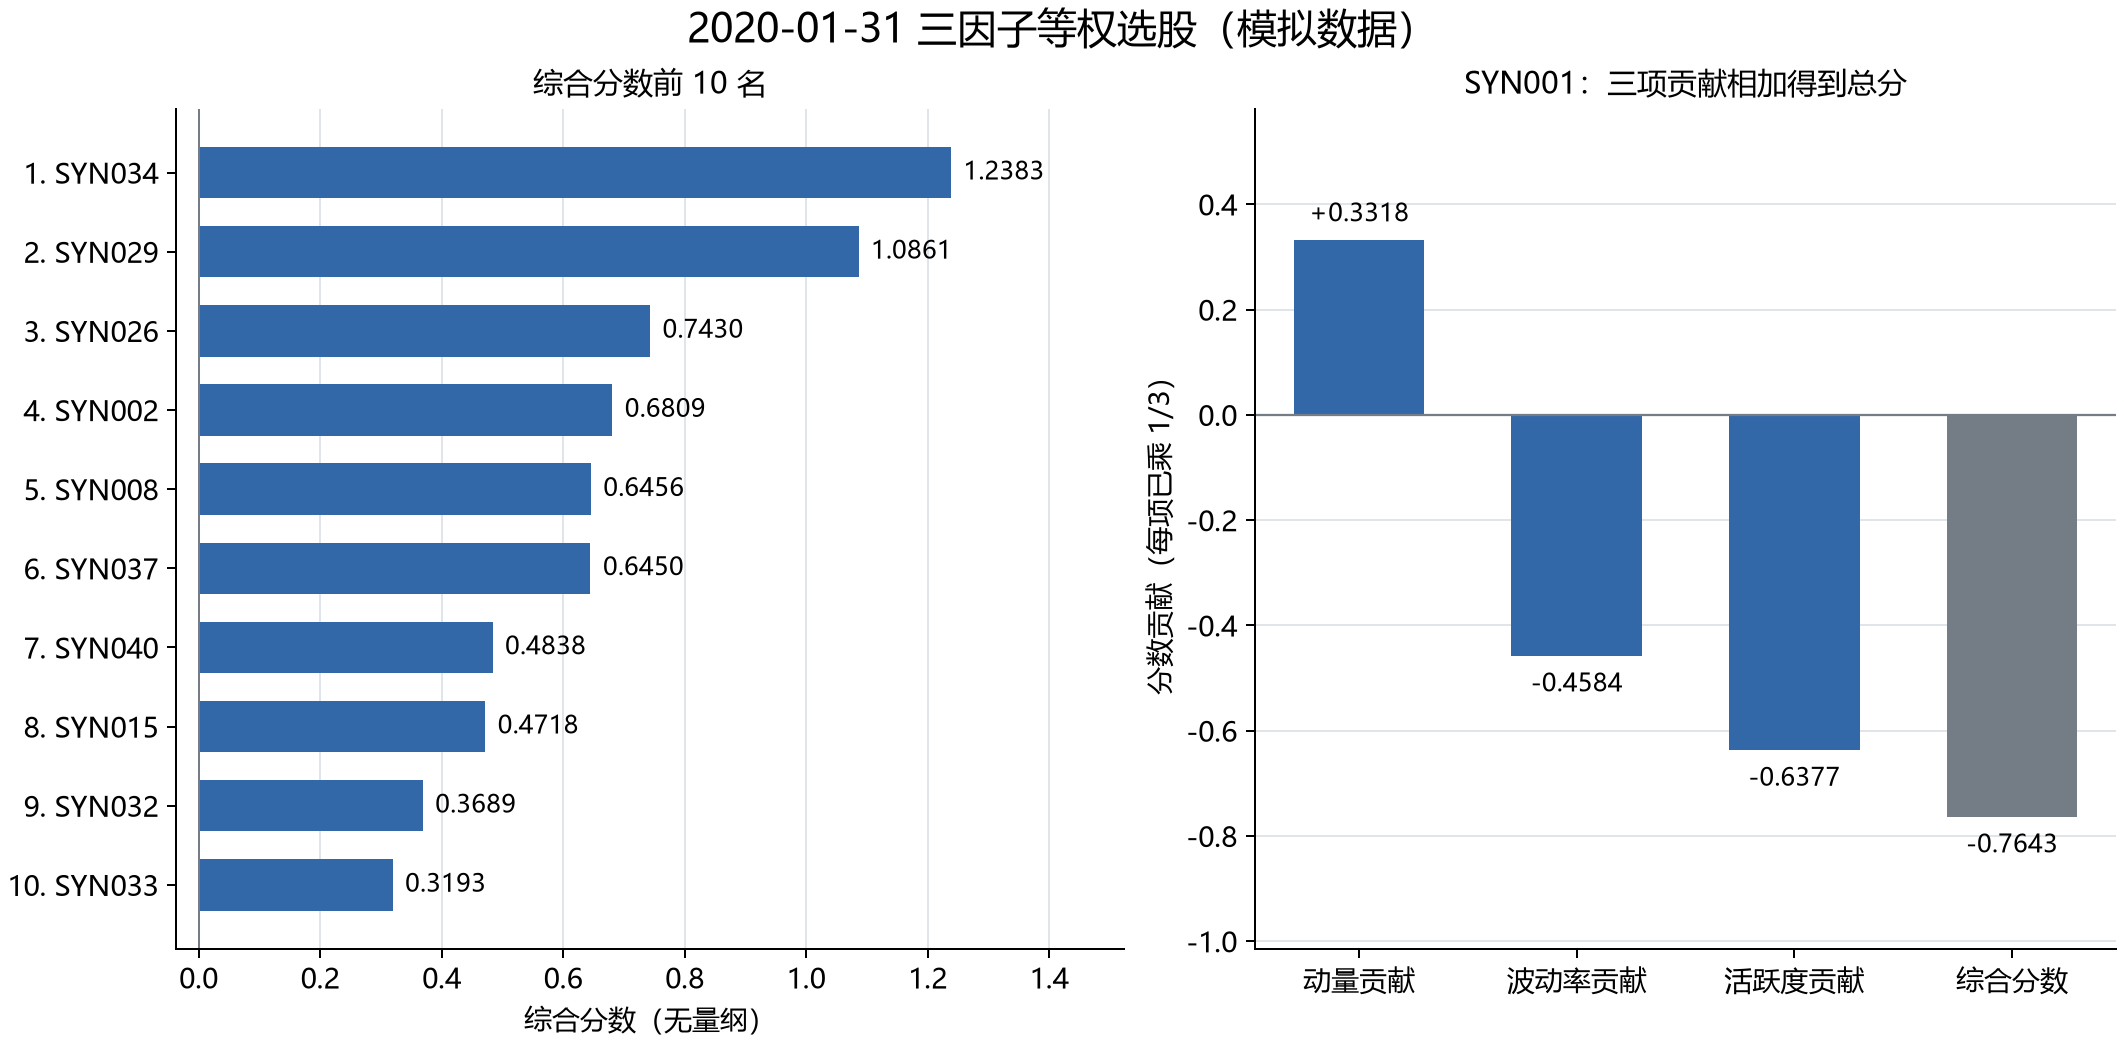

In [6]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/first_demo_20261107/lesson12_equal_weight_selection/composite_selection.png')))

## 我的复核

我在干净内核中按顺序执行以上实现；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。